**Eurovision Voting Blocs Across Eras (1975–2024)**

# 03 - Period Structure

**Objectives**
- Find the voting blocs of each period and test whether they are stronger than a random behavior
- Follow how blocs continue, appear or disappear from one period to the next
- Describe the structure of each period: mutual support, triads, key countries, core and periphery
- Check that the results hold under other network specifications
- Produce Figures 1–3 of the report

**Input:** networks exported by notebook 02 (`data/02_network_construction/`)

**Output:** tables (including `bloc_membership.csv`) in `data/03_period_structure/`, Figures 1–3 in `data/03_period_structure/figures/`

In [17]:
import os

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch
from sklearn.metrics import normalized_mutual_info_score

from helper_functions import best_louvain, shuffle_rows, uman_random_graph, coreness_scores, cp_fit

## 1. Setup

In [18]:
BASE = "../data/02_network_construction/"          # networks of notebook 02
OUT = "../data/03_period_structure/"     # tables of this notebook
FIG = OUT + "figures/"                   # figures of this notebook
os.makedirs(FIG, exist_ok=True)
PERIODS = ["P1", "P2", "P3", "P4"]

In [19]:
adj = {}
graphs = {}
for p in PERIODS:
    A = pd.read_csv(BASE + f"{p}_adj_topk3.csv", index_col=0)
    adj[p] = A
    graphs[p] = nx.from_pandas_adjacency(A, create_using=nx.DiGraph)

In [20]:
for p in PERIODS:
    A, G = adj[p], graphs[p]
    print(p,
          "| nodes:", G.number_of_nodes(),
          "| directed edges:", G.number_of_edges(),
          "| rows == columns:", list(A.index) == list(A.columns))

P1 | nodes: 35 | directed edges: 518 | rows == columns: True
P2 | nodes: 48 | directed edges: 615 | rows == columns: True
P3 | nodes: 47 | directed edges: 536 | rows == columns: True
P4 | nodes: 45 | directed edges: 686 | rows == columns: True


In [21]:
# preview of the P1 matrix
print(adj["P1"].iloc[:5, :5].round(2))

      AUT   BEL  BIH   CHE   CYP
AUT  0.00  0.00  0.0  0.30  0.00
BEL  0.15  0.00  0.0  0.30  0.07
BIH  0.25  0.00  0.0  0.00  0.00
CHE  0.05  0.10  0.0  0.00  0.07
CYP  0.13  0.14  0.0  0.14  0.00


## 2. Voting Blocs

### 2.1. Louvain Community Detection

A bloc here is a group of countries that give most of their support to each other.

Modularity (Q) scores a division of the countries into groups: it measures how much of the voting weight stays *inside* the groups, minus what would stay inside if votes were spread at random. Q = 0 means no group structure.

Louvain is an algorithm that looks for the division with the highest modularity. It starts with every country in its own group, moves each country to the neighbouring group that increases Q the most, then merges the groups into single nodes and repeats until nothing improves. Because the result depends on the random order in which countries are visited, it is run with 100 seeds and the division with the highest Q is kept (`best_louvain`, in `helper_functions.py`).

*Seed check done before:* rerunning the "best of 100" with five other blocks of 100 seeds gives exactly the same blocs in P2–P4; in P1 only Austria changes bloc in two of the five blocks.

In [22]:
# apply to each period
partitions = {}
modularity_obs = {}

for p in PERIODS:
    blocs, q = best_louvain(graphs[p])
    blocs = sorted(blocs, key=len, reverse=True)
    partitions[p] = blocs
    modularity_obs[p] = q
    print(f"\n{p}: {len(blocs)} blocs, modularity Q = {q:.3f}")
    for i, b in enumerate(blocs, start=1):
        print(f"  Bloc {i} ({len(b)} countries): {', '.join(sorted(b))}")


P1: 3 blocs, modularity Q = 0.180
  Bloc 1 (16 countries): AUT, BEL, CHE, DEU, ESP, FRA, GBR, ISR, ITA, LUX, MAR, MCO, NLD, PRT, TUR, YUG
  Bloc 2 (12 countries): DNK, EST, FIN, HUN, IRL, ISL, LTU, NOR, POL, RUS, SVN, SWE
  Bloc 3 (7 countries): BIH, CYP, GRC, HRV, MLT, ROU, SVK

P2: 4 blocs, modularity Q = 0.298
  Bloc 1 (14 countries): ALB, AUT, BIH, CHE, DEU, HRV, MKD, MLT, MNE, SCG, SRB, SVK, SVN, TUR
  Bloc 2 (13 countries): AND, BEL, BGR, CYP, ESP, FRA, GRC, HUN, ISR, NLD, PRT, ROU, SMR
  Bloc 3 (13 countries): DNK, EST, FIN, GBR, IRL, ISL, ITA, LTU, LVA, MCO, NOR, POL, SWE
  Bloc 4 (8 countries): ARM, AZE, BLR, CZE, GEO, MDA, RUS, UKR

P3: 4 blocs, modularity Q = 0.297
  Bloc 1 (19 countries): AUS, AUT, BEL, CHE, DEU, DNK, EST, FIN, GBR, HUN, IRL, ISL, LTU, LVA, NLD, NOR, POL, SVK, SWE
  Bloc 2 (10 countries): AND, ESP, FRA, ISR, ITA, MDA, MLT, PRT, ROU, SMR
  Bloc 3 (10 countries): ARM, AZE, BGR, BLR, CYP, CZE, GEO, GRC, RUS, UKR
  Bloc 4 (8 countries): ALB, BIH, HRV, MKD, MNE

### 2.2. Are the Blocs Real? Permutation Test Against Null Networks

Louvain always returns some groups, even on random data, so a value of Q alone proves nothing. The observed Q is compared with Q computed on null networks: copies of the real network in which each country keeps exactly the weights it gives (how much and how unevenly it votes) but the receivers of these weights are shuffled at random. This destroys whom each country favours, which is exactly what an alliance is. Each null network is built by `shuffle_rows` (in `helper_functions.py`).

With 500 null networks:

- z-score: how many standard deviations the real network is above chance.

$$z = \frac{Q_{\text{observed}} - \text{mean}(Q_{\text{null}})}{\text{sd}(Q_{\text{null}})}$$

- p-value, where $b$ is the number of null networks that reach the observed Q:

$$p = \frac{b + 1}{500 + 1}$$

In [23]:
# permutation test for each period
N_PERM = 500
rng = np.random.default_rng(2024)
perm_results = []
null_q = {}

for p in PERIODS:
    nulls = []
    for k in range(N_PERM):
        A_rand = shuffle_rows(adj[p], rng)
        G_rand = nx.from_pandas_adjacency(A_rand, create_using=nx.DiGraph)
        _, q_rand = best_louvain(G_rand, n_runs=10)
        nulls.append(q_rand)
    nulls = np.array(nulls)
    null_q[p] = nulls

    q_obs = modularity_obs[p]
    z = (q_obs - nulls.mean()) / nulls.std()
    p_val = (np.sum(nulls >= q_obs) + 1) / (N_PERM + 1)
    perm_results.append({"period": p,
                         "n_blocs": len(partitions[p]),
                         "Q_observed": round(q_obs, 3),
                         "Q_null_mean": round(nulls.mean(), 3),
                         "Q_null_sd": round(nulls.std(), 3),
                         "Q_null_max": round(nulls.max(), 3),
                         "z_score": round(z, 1),
                         "p_value": round(p_val, 4)})
    print(p, "done")

perm_table = pd.DataFrame(perm_results)
perm_table

P1 done
P2 done
P3 done
P4 done


,period,n_blocs,Q_observed,Q_null_mean,Q_null_sd,Q_null_max,z_score,p_value
0,P1,3,0.180,0.151,0.009,0.181,3.2,0.006
1,P2,4,0.298,0.189,0.008,0.215,13.0,0.002
2,P3,4,0.297,0.189,0.009,0.212,12.6,0.002
3,P4,4,0.207,0.153,0.008,0.181,7.2,0.002


### 2.3. Export the Bloc Membership

One row per country and period with its bloc number, used by the analyses of how blocs change between periods.

In [24]:
# one row per country per period
rows = []
for p in PERIODS:
    for bloc_id, bloc in enumerate(partitions[p], start=1):
        for iso3 in sorted(bloc):
            rows.append({"iso3": iso3, "period": p, "bloc_id": bloc_id})
bloc_membership = pd.DataFrame(rows)

# checks
print("Total rows:", len(bloc_membership))
print(bloc_membership.groupby("period")["iso3"].count())
print("Duplicated country-period pairs:",
      bloc_membership.duplicated(["iso3", "period"]).sum())

# save
bloc_membership.to_csv(OUT + "bloc_membership.csv", index=False)
perm_table.to_csv(OUT + "modularity_permutation_test.csv", index=False)

bloc_membership.head(10)

Total rows: 175
period
P1    35
P2    48
P3    47
P4    45
Name: iso3, dtype: int64
Duplicated country-period pairs: 0


,iso3,period,bloc_id
0,AUT,P1,1
1,BEL,P1,1
2,CHE,P1,1
3,DEU,P1,1
4,ESP,P1,1
5,FRA,P1,1
6,GBR,P1,1
7,ISR,P1,1
8,ITA,P1,1
9,LUX,P1,1


The checks confirm that every country appears exactly once in each period it took part in: 175 rows (35 countries in P1, 48 in P2, 47 in P3 and 45 in P4) and no duplicated country–period pair.

The preview shows the first rows of the table: `iso3` is the country, `period` the period and `bloc_id` its bloc in that period. Blocs are numbered from the largest (1) to the smallest, separately in each period, so bloc 1 of P1 is not the same bloc as bloc 1 of P2.

## 3. How Blocs Change Between Periods

### 3.1. Jaccard Overlap and Bloc Events

The Jaccard index of two groups is the number of members they share divided by the number of members in at least one of them. For example, {A, B, C, D} and {A, B, C, E} share 3 of 5 countries, so J = 0.6.

Every bloc of a period is compared with every bloc of the previous period. Its best predecessor is the earlier bloc with the highest Jaccard index, and the bloc is classified as:

- continues if that best overlap is at least 0.3;
- new / reorganised otherwise.

A bloc of the earlier period with no successor above 0.3 is reported as dissolved or split. Countries absent from the previous period are listed as new entrants.

In [25]:
# bloc members and countries present in each period
blocs_of = {p: {i: set(b) for i, b in enumerate(partitions[p], start=1)} for p in PERIODS}
countries_of = {p: set(graphs[p].nodes()) for p in PERIODS}

# Jaccard overlap between the blocs of consecutive periods
overlap_rows = []
for p_prev, p_next in zip(PERIODS[:-1], PERIODS[1:]):
    for i, A in blocs_of[p_prev].items():
        for j, B in blocs_of[p_next].items():
            shared = A & B
            overlap_rows.append({"from_period": p_prev, "from_bloc": i,
                                 "to_period": p_next, "to_bloc": j,
                                 "n_shared": len(shared),
                                 "jaccard": round(len(shared) / len(A | B), 2),
                                 "shared_countries": ", ".join(sorted(shared))})
overlap = pd.DataFrame(overlap_rows)

# overlap matrices (rows = earlier period, columns = later period)
for p_prev, p_next in zip(PERIODS[:-1], PERIODS[1:]):
    sub = overlap[overlap["from_period"] == p_prev]
    print(f"\nJaccard overlap {p_prev} (rows) -> {p_next} (columns)")
    print(sub.pivot(index="from_bloc", columns="to_bloc", values="jaccard"))

# best predecessor, event and new countries of each bloc
THRESHOLD = 0.3
event_rows = []
for p_prev, p_next in zip(PERIODS[:-1], PERIODS[1:]):
    for j, B in blocs_of[p_next].items():
        cand = overlap[(overlap["to_period"] == p_next) & (overlap["to_bloc"] == j)]
        best = cand.sort_values("jaccard", ascending=False).iloc[0]
        new_countries = sorted(B - countries_of[p_prev])
        event_rows.append({"period": p_next, "bloc_id": j, "size": len(B),
                           "best_predecessor": f"{p_prev} bloc {best['from_bloc']}",
                           "jaccard": best["jaccard"],
                           "event": "continues" if best["jaccard"] >= THRESHOLD else "new / reorganised",
                           "n_new_entrants": len(new_countries),
                           "new_entrants": ", ".join(new_countries)})
bloc_events = pd.DataFrame(event_rows)

# blocs with no successor (dissolved or split)
print()
for p_prev, p_next in zip(PERIODS[:-1], PERIODS[1:]):
    for i in blocs_of[p_prev]:
        best_next = overlap[(overlap["from_period"] == p_prev) &
                            (overlap["from_bloc"] == i)]["jaccard"].max()
        if best_next < THRESHOLD:
            print(f"{p_prev} bloc {i}: no successor in {p_next} "
                  f"(max Jaccard = {best_next}) -> dissolved / split")

# save
overlap.to_csv(OUT + "bloc_overlap.csv", index=False)
bloc_events.to_csv(OUT + "bloc_events.csv", index=False)
bloc_events


Jaccard overlap P1 (rows) -> P2 (columns)
to_bloc       1     2     3     4
from_bloc                        
1          0.15  0.26  0.12  0.00
2          0.04  0.04  0.56  0.05
3          0.24  0.18  0.00  0.00

Jaccard overlap P2 (rows) -> P3 (columns)
to_bloc       1     2     3     4
from_bloc                        
1          0.14  0.04  0.00  0.57
2          0.10  0.44  0.15  0.00
3          0.52  0.05  0.00  0.00
4          0.00  0.06  0.64  0.00

Jaccard overlap P3 (rows) -> P4 (columns)
to_bloc       1     2     3     4
from_bloc                        
1          0.67  0.00  0.00  0.20
2          0.04  0.32  0.12  0.00
3          0.04  0.47  0.00  0.07
4          0.00  0.00  0.70  0.00

P1 bloc 1: no successor in P2 (max Jaccard = 0.26) -> dissolved / split
P1 bloc 3: no successor in P2 (max Jaccard = 0.24) -> dissolved / split


,period,bloc_id,size,best_predecessor,jaccard,event,n_new_entrants,new_entrants
0,P2,1,14,P1 bloc 3,0.24,new / reorganised,5,"ALB, MKD, MNE, SCG, SRB"
1,P2,2,13,P1 bloc 1,0.26,new / reorganised,3,"AND, BGR, SMR"
2,P2,3,13,P1 bloc 2,0.56,continues,1,LVA
3,P2,4,8,P1 bloc 2,0.05,new / reorganised,7,"ARM, AZE, BLR, CZE, GEO, MDA, UKR"
4,P3,1,19,P2 bloc 3,0.52,continues,1,AUS
5,P3,2,10,P2 bloc 2,0.44,continues,0,
6,P3,3,10,P2 bloc 4,0.64,continues,0,
7,P3,4,8,P2 bloc 1,0.57,continues,0,
8,P4,1,16,P3 bloc 1,0.67,continues,0,
9,P4,2,15,P3 bloc 3,0.47,continues,1,LUX


## 4. Density and Reciprocity

These two measures use the binary networks of stable ties (weight ≥ 0.5 in at least two finals), because they only ask whether a tie exists:

- Density: share of all possible ties A → B that exist;
- Reciprocity: of all stable ties A → B, the share for which B → A also exists ("are alliances mutual?");
- Reciprocity vs random: reciprocity divided by density. In a random network a tie is returned with probability equal to the density, so a ratio of 5 means mutual ties are five times more frequent than chance.

`density_weighted_any_vote` is the density of the weighted network (any top-3 vote at all), shown only for comparison.

In [26]:
# load the binary networks
bin_graphs = {}
for p in PERIODS:
    B = pd.read_csv(BASE + f"{p}_adj_binary_t05.csv", index_col=0)
    bin_graphs[p] = nx.from_pandas_adjacency(B, create_using=nx.DiGraph)

# density and reciprocity of each period
basic_rows = []
for p in PERIODS:
    G = bin_graphs[p]
    dens = nx.density(G)
    recip = nx.reciprocity(G)
    mutual_pairs = sum(1 for u, v in G.edges() if G.has_edge(v, u)) // 2
    basic_rows.append({"period": p,
                       "n_countries": G.number_of_nodes(),
                       "density_weighted_any_vote": round(nx.density(graphs[p]), 3),
                       "binary_edges": G.number_of_edges(),
                       "density_binary": round(dens, 3),
                       "reciprocity": round(recip, 3),
                       "reciprocity_vs_random": round(recip / dens, 1),
                       "mutual_pairs": mutual_pairs,
                       "isolated_countries": len(list(nx.isolates(G)))})

basic_table = pd.DataFrame(basic_rows)
basic_table

,period,n_countries,density_weighted_any_vote,binary_edges,density_binary,reciprocity,reciprocity_vs_random,mutual_pairs,isolated_countries
0,P1,35,0.435,23,0.019,0.348,18.0,4,14
1,P2,48,0.273,112,0.050,0.357,7.2,20,6
2,P3,47,0.248,99,0.046,0.263,5.7,13,4
3,P4,45,0.346,101,0.051,0.198,3.9,10,2


In [27]:
# save the table
basic_table.to_csv(OUT + "basic_structure.csv", index=False)

## 5. Triad Census

### 5.1. What Is a Triad?

A triad is any group of three countries. Looking at the arrows between them, there are 16 possible shapes, named by the MAN code: the number of **M**utual pairs, **A**symmetric (one-way) pairs and **N**ull (unconnected) pairs, plus a letter for the direction when needed. Examples:

| Code | Shape | Reading |
|---|---|---|
| 003 | no arrows | three unrelated countries |
| 102 | A ↔ B, C alone | one mutual pair |
| 021U | A → C ← B | two countries support the same third one ("common target") |
| 021D | A → B, A → C | one voter supports two countries |
| 030T | A → B, B → C, A → C | transitive chain |
| 201, 120D/U/C, 210, 300 | two or three mutual pairs | closed, bloc-like triads |

The triad census counts how many triads of each shape the network has. The counts are compared with 1,000 random graphs with the same number of countries and stable ties (G(n, m) graphs, in which ties are placed completely at random). A ratio of 2 means the shape is twice as frequent as in random networks.

In [28]:
# the 16 triad types (MAN code: number of mutual, asymmetric and null pairs)
TRIAD_TYPES = ["003", "012", "102", "021D", "021U", "021C", "111D", "111U",
               "030T", "030C", "201", "120D", "120U", "120C", "210", "300"]

# groups of triad types
TRIAD_GROUPS = {
    "102_mutual_pair":            ["102"],
    "021U_common_target":         ["021U"],
    "021D_one_voter_two_targets": ["021D"],
    "030T_transitive":            ["030T"],
    "bloc_like_mutual_closed":    ["201", "120D", "120U", "120C", "210", "300"],
}

# observed triad census vs 1000 random graphs with the same number of nodes and edges
N_RAND = 1000
triad_rows = []
for p in PERIODS:
    G = bin_graphs[p]
    observed = nx.triadic_census(G)
    n, m = G.number_of_nodes(), G.number_of_edges()
    random_counts = []
    for s in range(N_RAND):
        R = nx.gnm_random_graph(n, m, seed=2024 + s, directed=True)
        random_counts.append(nx.triadic_census(R))
    random_counts = pd.DataFrame(random_counts)
    for t in TRIAD_TYPES:
        triad_rows.append({"period": p, "triad": t,
                           "observed": observed[t],
                           "expected_random": round(random_counts[t].mean(), 1)})
    print(p, "done")
triad_table = pd.DataFrame(triad_rows)

# observed, expected and ratio by group
group_rows = []
for p in PERIODS:
    sub = triad_table[triad_table["period"] == p].set_index("triad")
    for g, types in TRIAD_GROUPS.items():
        obs = sub.loc[types, "observed"].sum()
        exp = sub.loc[types, "expected_random"].sum()
        group_rows.append({"period": p, "group": g,
                           "observed": obs,
                           "expected_random": round(exp, 1),
                           "ratio": round(obs / exp, 1) if exp > 0 else None})
triad_groups = pd.DataFrame(group_rows)

# save
triad_table.to_csv(OUT + "triad_census.csv", index=False)
triad_groups.to_csv(OUT + "triad_groups.csv", index=False)
print("\nObserved counts:")
print(triad_groups.pivot(index="group", columns="period", values="observed"))
print("\nRatio observed / random:")
print(triad_groups.pivot(index="group", columns="period", values="ratio"))

P1 done
P2 done
P3 done
P4 done

Observed counts:
period                       P1   P2   P3   P4
group                                         
021D_one_voter_two_targets    3   26   31   49
021U_common_target           13  141  161  229
030T_transitive               0   10   16    9
102_mutual_pair             122  757  470  349
bloc_like_mutual_closed       4   39   21    9

Ratio observed / random:
period                        P1    P2    P3   P4
group                                            
021D_one_voter_two_targets   0.5   0.3   0.4  0.5
021U_common_target           2.0   1.4   1.9  2.6
030T_transitive              0.0   0.9   2.0  0.9
102_mutual_pair             20.7   7.3   5.5  4.0
bloc_like_mutual_closed      NaN  26.0  21.0  7.5


### 5.2. A Fairer Baseline: U|MAN Random Graphs

G(n, m) graphs have much less reciprocity than the real networks, so mutual-pair triads look over-represented almost automatically. U|MAN random graphs keep exactly the real numbers of **M**utual, **A**symmetric and **N**ull pairs and only shuffle which pairs they are (`uman_random_graph`, in `helper_functions.py`). The test therefore asks: given the amount of reciprocity the network already has, are bloc-like triads still more frequent than expected?

The p-value is the share of the 1,000 U|MAN graphs with at least as many triads of the group as the real network.

In [29]:
# observed triad census vs 1000 U|MAN random graphs
rng = np.random.default_rng(2024)
uman_rows = []
for p in PERIODS:
    G = bin_graphs[p]
    n_mutual = sum(1 for u, v in G.edges() if G.has_edge(v, u)) // 2
    n_asym = G.number_of_edges() - 2 * n_mutual
    observed = nx.triadic_census(G)
    sims = pd.DataFrame([nx.triadic_census(uman_random_graph(list(G.nodes()), n_mutual, n_asym, rng))
                         for _ in range(N_RAND)])
    for g, types in TRIAD_GROUPS.items():
        obs = sum(observed[t] for t in types)
        sim = sims[types].sum(axis=1)
        uman_rows.append({"period": p, "group": g,
                          "observed": obs,
                          "expected_UMAN": round(sim.mean(), 1),
                          "ratio": round(obs / sim.mean(), 1) if sim.mean() > 0 else None,
                          "p_value": round((np.sum(sim >= obs) + 1) / (N_RAND + 1), 3)})
    print(p, "done")

triad_uman = pd.DataFrame(uman_rows)
triad_uman.to_csv(OUT + "triad_groups_UMAN.csv", index=False)
print("\nRatio observed / U|MAN random:")
print(triad_uman.pivot(index="group", columns="period", values="ratio"))
print("\np-values:")
print(triad_uman.pivot(index="group", columns="period", values="p_value"))

P1 done
P2 done
P3 done
P4 done

Ratio observed / U|MAN random:
period                       P1   P2   P3   P4
group                                         
021D_one_voter_two_targets  1.1  0.5  0.6  0.8
021U_common_target          4.6  2.9  3.2  3.6
030T_transitive             0.0  3.1  4.4  1.6
102_mutual_pair             1.0  1.0  0.9  1.0
bloc_like_mutual_closed     5.2  2.0  2.3  1.3

p-values:
period                         P1     P2     P3     P4
group                                                 
021D_one_voter_two_targets  0.522  1.000  1.000  0.991
021U_common_target          0.001  0.001  0.001  0.001
030T_transitive             1.000  0.004  0.001  0.117
102_mutual_pair             0.821  0.955  0.997  0.803
bloc_like_mutual_closed     0.010  0.001  0.002  0.244


## 6. Key Countries: Centrality

- In-strength: sum of the weights a country receives, divided by the number of other countries. It is the average share of finals in which other countries put it in their top 3: how widely supported it is.
- Stable supporters: number of countries with a stable tie towards it in the binary network.
- Betweenness: how often a country lies on the shortest path between two other countries, i.e. how much it works as a bridge between groups. Strong ties should count as short distances, so the distance of an edge is 1 / weight.

Only countries with at least 3 finals in the period are listed in the top 5, to avoid shares based on one or two votes.

In [30]:
cent_rows = []
for p in PERIODS:
    G = graphs[p]
    Gb = bin_graphs[p]
    n = G.number_of_nodes()

    # number of finals of each country in the period
    E = pd.read_csv(BASE + f"{p}_edgelist_topk3.csv")
    years_in_final = E.groupby("to")["co_participation_years"].max()

    # in-strength: sum of incoming weights / (n - 1)
    in_str = dict(G.in_degree(weight="weight"))

    # betweenness, with distance = 1 / weight
    for u, v, d in G.edges(data=True):
        d["distance"] = 1 / d["weight"]
    btw = nx.betweenness_centrality(G, weight="distance", normalized=True)

    # Louvain bloc of each country
    bloc_of = {c: i for i, b in enumerate(partitions[p], start=1) for c in b}

    for c in G.nodes():
        cent_rows.append({"period": p, "iso3": c,
                          "bloc_id": bloc_of[c],
                          "years_in_final": int(years_in_final.get(c, 0)),
                          "in_strength": round(in_str[c] / (n - 1), 3),
                          "stable_supporters": Gb.in_degree(c),
                          "betweenness": round(btw[c], 3)})

centrality = pd.DataFrame(cent_rows)
centrality.to_csv(OUT + "centrality.csv", index=False)

# top 5 per period (countries with at least 3 finals)
MIN_YEARS = 3
for p in PERIODS:
    d = centrality[(centrality["period"] == p) &
                   (centrality["years_in_final"] >= MIN_YEARS)]
    print(f"\n===== {p} =====")
    print("Top 5 in-strength:")
    print(d.nlargest(5, "in_strength")[["iso3", "bloc_id", "years_in_final",
                                        "in_strength", "stable_supporters"]].to_string(index=False))
    print("Top 5 betweenness:")
    print(d.nlargest(5, "betweenness")[["iso3", "bloc_id", "years_in_final",
                                        "betweenness"]].to_string(index=False))


===== P1 =====
Top 5 in-strength:
iso3  bloc_id  years_in_final  in_strength  stable_supporters
 IRL        2              21        0.402                  5
 GBR        1              22        0.248                  1
 FRA        1              21        0.236                  0
 DEU        1              21        0.219                  0
 MLT        3               7        0.204                  4
Top 5 betweenness:
iso3  bloc_id  years_in_final  betweenness
 IRL        2              21        0.124
 MLT        3               7        0.119
 POL        2               3        0.102
 GBR        1              22        0.072
 SVN        2               3        0.042

===== P2 =====
Top 5 in-strength:
iso3  bloc_id  years_in_final  in_strength  stable_supporters
 ARM        4               3        0.284                 13
 RUS        4              10        0.276                  9
 UKR        4               6        0.260                 10
 GRC        2              10    

## 7. Core–Periphery Structure

Instead of several groups side by side, a network can have a core of countries strongly tied to each other and a periphery of countries tied mainly to the core and weakly to each other.

- Coreness (0–1) of each country: computed from the leading eigenvector of the symmetrised network (average of A → B and B → A). Countries with strong ties to other well-connected countries get high values. This is an approximation of Borgatti and Everett's continuous core–periphery model.
- Fit: correlation between the real tie strengths and the ideal pattern in which the tie between two countries is the product of their coreness values. The fit is tested against the same 500 null networks as modularity. Both measures are computed by `coreness_scores` and `cp_fit` (in `helper_functions.py`).

In [31]:
rng = np.random.default_rng(2024)
cp_rows, coreness_rows = [], []
for p in PERIODS:
    W = adj[p].values
    c, S = coreness_scores(W)
    fit_obs = cp_fit(S, c)

    # fit vs 500 random networks
    nulls = []
    for k in range(500):
        R = shuffle_rows(adj[p], rng).values
        cr, Sr = coreness_scores(R)
        nulls.append(cp_fit(Sr, cr))
    nulls = np.array(nulls)
    cp_rows.append({"period": p,
                    "cp_fit": round(fit_obs, 3),
                    "fit_null_mean": round(nulls.mean(), 3),
                    "fit_null_sd": round(nulls.std(), 3),
                    "z_score": round((fit_obs - nulls.mean()) / nulls.std(), 1),
                    "p_value": round((np.sum(nulls >= fit_obs) + 1) / 501, 3)})

    # coreness and number of finals of each country
    years = centrality[centrality["period"] == p].set_index("iso3")["years_in_final"]
    for country, value in zip(adj[p].index, c):
        coreness_rows.append({"period": p, "iso3": country,
                              "coreness": round(value, 3),
                              "years_in_final": int(years[country])})
    print(p, "done")

cp_table = pd.DataFrame(cp_rows)
coreness_df = pd.DataFrame(coreness_rows)
cp_table.to_csv(OUT + "core_periphery_fit.csv", index=False)
coreness_df.to_csv(OUT + "coreness.csv", index=False)

# core and periphery countries (at least 3 finals)
for p in PERIODS:
    d = coreness_df[(coreness_df["period"] == p) & (coreness_df["years_in_final"] >= 3)]
    d = d.sort_values("coreness", ascending=False)
    print(f"\n{p}  core:     ", ", ".join(f"{r.iso3} {r.coreness:.2f}" for r in d.head(5).itertuples()))
    print(f"{p}  periphery:", ", ".join(f"{r.iso3} {r.coreness:.2f}" for r in d.tail(5).itertuples()))

# coreness vs in-strength
merged = coreness_df.merge(centrality, on=["period", "iso3"])
print("\nCorrelation coreness vs in-strength:")
print(merged.groupby("period")[["coreness", "in_strength"]].corr().xs("in_strength", level=1)["coreness"].round(2))

cp_table

P1 done
P2 done
P3 done
P4 done

P1  core:      IRL 1.00, GBR 0.76, FRA 0.69, SWE 0.65, DEU 0.63
P1  periphery: BEL 0.41, HRV 0.37, TUR 0.36, PRT 0.36, BIH 0.28

P2  core:      RUS 1.00, UKR 0.88, ARM 0.81, GRC 0.74, TUR 0.62
P2  periphery: AUT 0.31, IRL 0.30, ISL 0.29, NOR 0.26, PRT 0.25

P3  core:      SWE 1.00, NOR 0.74, DNK 0.68, AUT 0.66, AZE 0.64
P3  periphery: LTU 0.30, CYP 0.28, ESP 0.25, MDA 0.23, BLR 0.23

P4  core:      ITA 1.00, RUS 1.00, UKR 0.96, CHE 0.93, BGR 0.92
P4  periphery: EST 0.40, DEU 0.40, POL 0.39, DNK 0.38, HUN 0.36

Correlation coreness vs in-strength:
period
P1    0.95
P2    0.91
P3    0.93
P4    0.95
Name: coreness, dtype: float64


,period,cp_fit,fit_null_mean,fit_null_sd,z_score,p_value
0,P1,0.427,0.199,0.023,10.0,0.002
1,P2,0.339,0.189,0.018,8.4,0.002
2,P3,0.375,0.178,0.020,10.0,0.002
3,P4,0.389,0.177,0.019,11.4,0.002


## 8. Robustness Checks

### 8.1. Alternative Weighted Networks

Blocs, modularity test and core–periphery fit are recomputed on:

- networks with k = 2 and k = 4 instead of k = 3;
- rank-based weights (1st place → 1.0, …, 10th → 0.1);
- P1 divided at 1993 into 1975–1992 (P1a) and 1993–1996 (P1b), to check whether P1's blocs exist before the Eastern European countries entered.

NMI (Normalised Mutual Information) compares each alternative partition with the main one: 1 = identical divisions, close to 0 = unrelated.

In [32]:
# alternative weighted networks (built in notebook 02)
ROB = BASE + "robustness/"
alt_nets = {}
for p in PERIODS:
    alt_nets[(p, "k=2")]  = pd.read_csv(ROB + f"{p}_adj_topk2.csv", index_col=0)
    alt_nets[(p, "k=4")]  = pd.read_csv(ROB + f"{p}_adj_topk4.csv", index_col=0)
    alt_nets[(p, "rank")] = pd.read_csv(ROB + f"{p}_adj_rank.csv", index_col=0)
alt_nets[("P1a", "k=3")] = pd.read_csv(ROB + "P1a_adj_topk3.csv", index_col=0)
alt_nets[("P1b", "k=3")] = pd.read_csv(ROB + "P1b_adj_topk3.csv", index_col=0)

# main partition: country -> bloc
main_label = {p: {c: i for i, b in enumerate(partitions[p], start=1) for c in b} for p in PERIODS}

# blocs, modularity test, NMI with the main partition and core-periphery test of each alternative
N_PERM_ROB = 200
rng = np.random.default_rng(2024)
rob_rows, alt_partitions = [], {}
for (p, variant), A in alt_nets.items():
    G = nx.from_pandas_adjacency(A, create_using=nx.DiGraph)
    blocs, q = best_louvain(G)
    alt_partitions[(p, variant)] = blocs
    c, S = coreness_scores(A.values)
    fit = cp_fit(S, c)

    q_null, fit_null = [], []
    for k in range(N_PERM_ROB):
        A_rand = shuffle_rows(A, rng)
        q_null.append(best_louvain(nx.from_pandas_adjacency(A_rand, create_using=nx.DiGraph), n_runs=10)[1])
        cr, Sr = coreness_scores(A_rand.values)
        fit_null.append(cp_fit(Sr, cr))
    q_null, fit_null = np.array(q_null), np.array(fit_null)

    ref = "P1" if p.startswith("P1") else p                 # P1a and P1b are compared with P1
    label = {c: i for i, b in enumerate(blocs) for c in b}
    common = [c for c in label if c in main_label[ref]]
    nmi = normalized_mutual_info_score([main_label[ref][c] for c in common],
                                       [label[c] for c in common])
    rob_rows.append({"period": p, "variant": variant,
                     "n_blocs": len(blocs),
                     "Q": round(q, 3),
                     "Q_z": round((q - q_null.mean()) / q_null.std(), 1),
                     "Q_p": round((np.sum(q_null >= q) + 1) / (N_PERM_ROB + 1), 3),
                     "NMI_vs_main": round(nmi, 2),
                     "CP_z": round((fit - fit_null.mean()) / fit_null.std(), 1)})
    print(p, variant, "done")

robust_table = pd.DataFrame(rob_rows)
robust_table.to_csv(OUT + "robustness_weighted.csv", index=False)
print(robust_table.to_string(index=False))

# bloc containing RUS and SRB (and UKR in P4) in each version
for p in ["P2", "P4"]:
    print(f"\n===== {p} =====")
    versions = [("main k=3", partitions[p])] + [(v, alt_partitions[(p, v)]) for v in ["k=2", "k=4", "rank"]]
    for name, blocs in versions:
        for country in ["RUS", "SRB"] + (["UKR"] if p == "P4" else []):
            members = sorted(next(b for b in blocs if country in b))
            print(f"{name:9s} {country}: {', '.join(members)}")

# blocs in the two halves of P1
for p in ["P1a", "P1b"]:
    print(f"\n{p}:")
    for i, b in enumerate(sorted(alt_partitions[(p, "k=3")], key=len, reverse=True), start=1):
        print(f"  Bloc {i}: {', '.join(sorted(b))}")

P1 k=2 done
P1 k=4 done
P1 rank done
P2 k=2 done
P2 k=4 done
P2 rank done
P3 k=2 done
P3 k=4 done
P3 rank done
P4 k=2 done
P4 k=4 done
P4 rank done
P1a k=3 done
P1b k=3 done
period variant  n_blocs     Q  Q_z   Q_p  NMI_vs_main  CP_z
    P1     k=2        5 0.218  2.1 0.045         0.62   8.7
    P1     k=4        4 0.152  3.3 0.005         0.47  11.9
    P1    rank        3 0.112  6.3 0.005         0.72  15.2
    P2     k=2        4 0.357 10.7 0.005         0.51   5.8
    P2     k=4        5 0.240 11.2 0.005         0.66  10.0
    P2    rank        4 0.162 14.2 0.005         0.58  13.0
    P3     k=2        4 0.357 11.3 0.005         0.59   8.1
    P3     k=4        4 0.256 12.6 0.005         0.86  11.6
    P3    rank        4 0.180 16.4 0.005         0.61  15.7
    P4     k=2        5 0.254  6.2 0.005         0.62   7.8
    P4     k=4        4 0.179  8.4 0.005         0.65  13.7
    P4    rank        4 0.130 10.8 0.005         0.61  17.0
   P1a     k=3        4 0.089 -1.1 0.861      

### 8.2. Binary Threshold 0.33

Reciprocity and triad results recomputed on the binary networks with τ = 0.33 (a tie needs B in A's top 3 in at least one third of the finals, and in at least two finals).

In [33]:
# binary measures with τ = 0.33
rng = np.random.default_rng(2024)
t033_rows = []
for p in PERIODS:
    G = nx.from_pandas_adjacency(pd.read_csv(ROB + f"{p}_adj_binary_t033.csv", index_col=0),
                                 create_using=nx.DiGraph)
    n_mutual = sum(1 for u, v in G.edges() if G.has_edge(v, u)) // 2
    n_asym = G.number_of_edges() - 2 * n_mutual
    observed = nx.triadic_census(G)
    sims = pd.DataFrame([nx.triadic_census(uman_random_graph(list(G.nodes()), n_mutual, n_asym, rng))
                         for _ in range(N_RAND)])
    row = {"period": p,
           "edges": G.number_of_edges(),
           "density": round(nx.density(G), 3),
           "reciprocity": round(nx.reciprocity(G), 3)}
    for g in ["bloc_like_mutual_closed", "021U_common_target", "030T_transitive"]:
        types = TRIAD_GROUPS[g]
        obs = sum(observed[t] for t in types)
        sim = sims[types].sum(axis=1)
        row[g + "_ratio"] = round(obs / sim.mean(), 1)
        row[g + "_p"] = round((np.sum(sim >= obs) + 1) / (N_RAND + 1), 3)
    t033_rows.append(row)
    print(p, "done")

t033_table = pd.DataFrame(t033_rows)
t033_table.to_csv(OUT + "robustness_binary_t033.csv", index=False)
print("\nMain results (threshold 0.5) for comparison:")
print("reciprocity:", dict(zip(basic_table["period"], basic_table["reciprocity"])))
print("\nThreshold 0.33:")
print(t033_table.set_index("period").T)

P1 done
P2 done
P3 done
P4 done

Main results (threshold 0.5) for comparison:
reciprocity: {'P1': 0.348, 'P2': 0.357, 'P3': 0.263, 'P4': 0.198}

Threshold 0.33:
period                             P1       P2       P3       P4
edges                          78.000  160.000  156.000  163.000
density                         0.066    0.071    0.072    0.082
reciprocity                     0.205    0.312    0.308    0.196
bloc_like_mutual_closed_ratio   2.400    1.800    1.800    1.700
bloc_like_mutual_closed_p       0.003    0.001    0.001    0.005
021U_common_target_ratio        3.600    2.300    3.700    3.000
021U_common_target_p            0.001    0.001    0.001    0.001
030T_transitive_ratio           5.200    2.100    2.500    2.900
030T_transitive_p               0.001    0.002    0.001    0.001


### 8.3. Jaccard Thresholds

Bloc events recomputed with Jaccard thresholds 0.2 and 0.5 instead of 0.3.

In [34]:
# bloc matching with Jaccard thresholds 0.2, 0.3 (main) and 0.5
jac_rob = bloc_events[["period", "bloc_id", "size", "best_predecessor",
                       "jaccard", "n_new_entrants"]].copy()
for th in [0.2, 0.3, 0.5]:
    jac_rob[f"event_{th}"] = np.where(jac_rob["jaccard"] >= th, "continues", "new")
jac_rob.to_csv(OUT + "robustness_jaccard.csv", index=False)
print(jac_rob.to_string(index=False))

# blocs with no successor under each threshold
print()
for th in [0.2, 0.3, 0.5]:
    dissolved = []
    for p_prev, p_next in zip(PERIODS[:-1], PERIODS[1:]):
        for i in blocs_of[p_prev]:
            best_next = overlap[(overlap["from_period"] == p_prev) &
                                (overlap["from_bloc"] == i)]["jaccard"].max()
            if best_next < th:
                dissolved.append(f"{p_prev} bloc {i} ({best_next})")
    print(f"Threshold {th}: no successor -> {', '.join(dissolved) if dissolved else 'none'}")

period  bloc_id  size best_predecessor  jaccard  n_new_entrants event_0.2 event_0.3 event_0.5
    P2        1    14        P1 bloc 3     0.24               5 continues       new       new
    P2        2    13        P1 bloc 1     0.26               3 continues       new       new
    P2        3    13        P1 bloc 2     0.56               1 continues continues continues
    P2        4     8        P1 bloc 2     0.05               7       new       new       new
    P3        1    19        P2 bloc 3     0.52               1 continues continues continues
    P3        2    10        P2 bloc 2     0.44               0 continues continues       new
    P3        3    10        P2 bloc 4     0.64               0 continues continues continues
    P3        4     8        P2 bloc 1     0.57               0 continues continues continues
    P4        1    16        P3 bloc 1     0.67               0 continues continues continues
    P4        2    15        P3 bloc 3     0.47             

## 9. Figures

### 9.1. Figure 1: Blocs in the Four Periods

Schematic map: countries keep their relative geographic position. Colour and shape show the bloc *lineage* (a bloc and its successors across periods), node size the in-strength, lines the stable ties (darker = mutual).

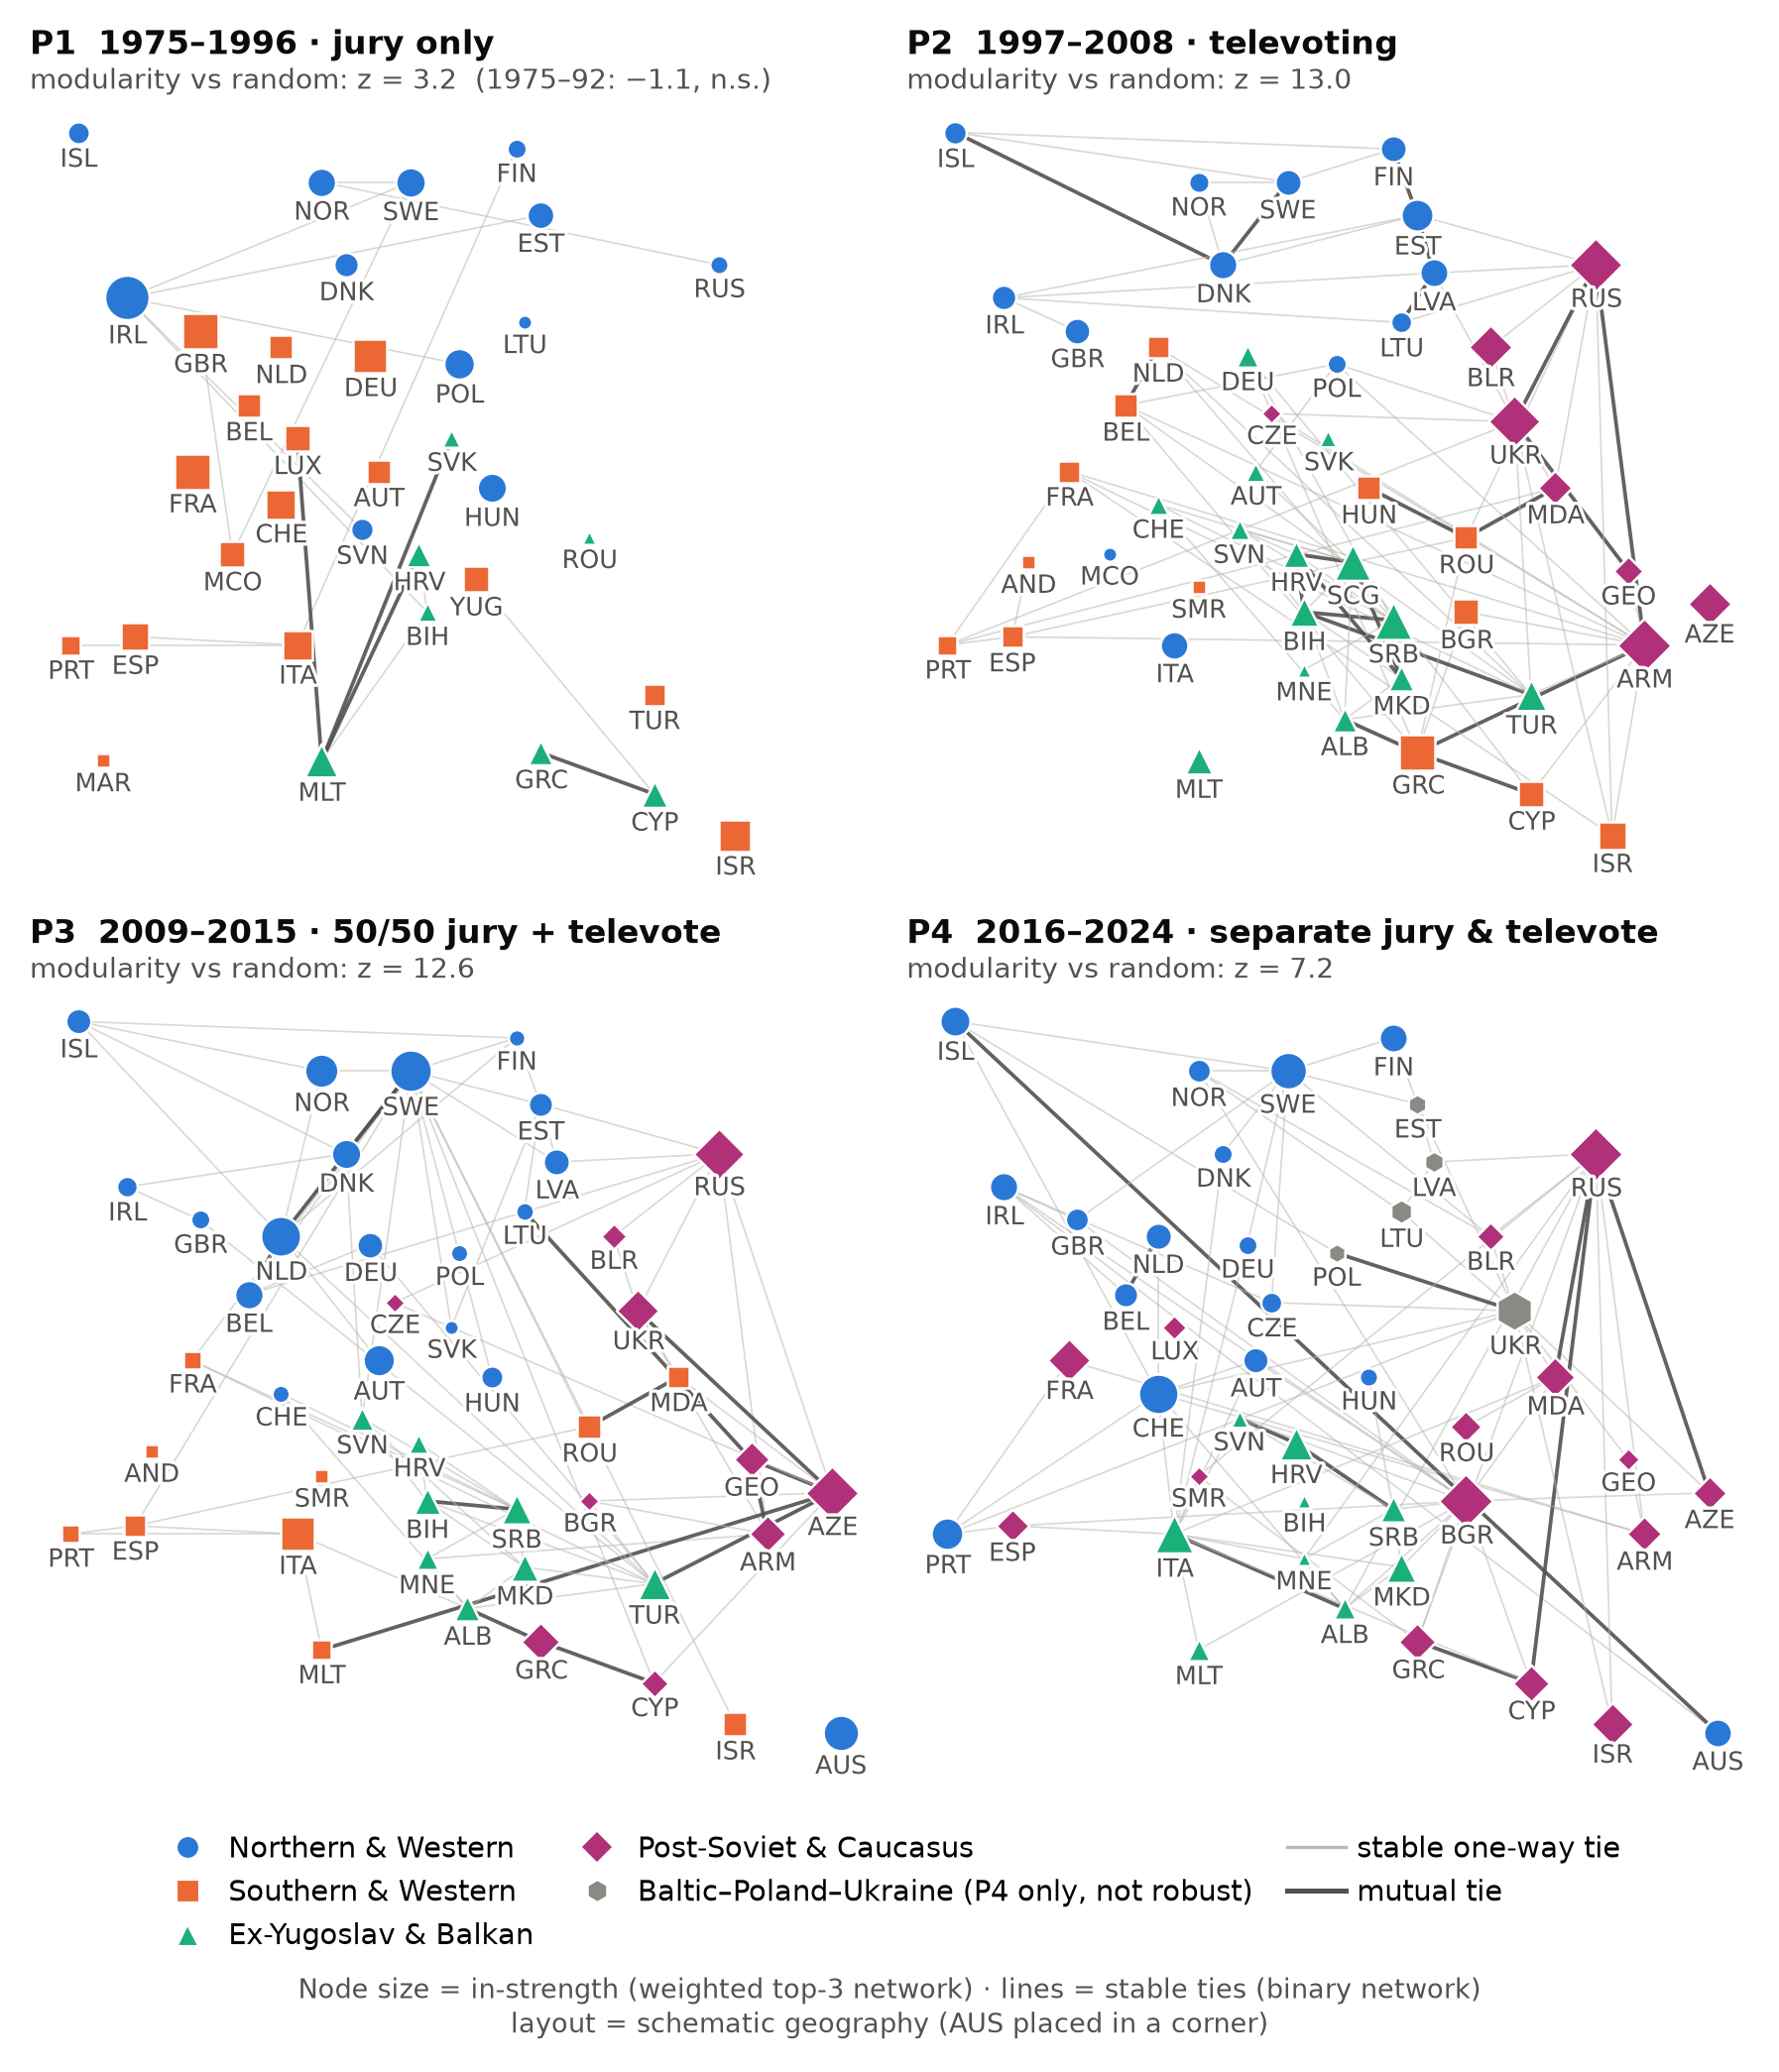

In [35]:
# figure 1: voting blocs in the four eras

# schematic map: relative geographic positions, spread out so that labels do not overlap
POS = {
 "ISL":(3,90),
 "NOR":(33,84),"SWE":(44,84),"FIN":(57,88),"EST":(60,80),
 "IRL":(9,70),"GBR":(18,66),"DNK":(36,74),"LVA":(62,73),"LTU":(58,67),"RUS":(82,74),
 "NLD":(28,64),"DEU":(39,63),"POL":(50,62),"BLR":(69,64),
 "BEL":(24,57),"LUX":(30,53),"CZE":(42,56),"UKR":(72,55),
 "FRA":(17,49),"CHE":(28,45),"AUT":(40,49),"SVK":(49,53),"HUN":(54,47),"MDA":(77,47),
 "MCO":(22,39),"SVN":(38,42),"HRV":(45,39),"ROU":(66,41),
 "AND":(12,38),"SMR":(33,35),"BIH":(46,32),"YUG":(52,36),"SCG":(52,38),"SRB":(57,31),
 "PRT":(2,28),"ESP":(10,29),"ITA":(30,28),"MNE":(46,25),"MKD":(58,24),"BGR":(66,32),
 "GEO":(86,37),"AZE":(96,33),"ARM":(88,28),
 "ALB":(51,19),"TUR":(74,22),"GRC":(60,15),"MLT":(33,14),"CYP":(74,10),"ISR":(84,5),
 "MAR":(6,14),"AUS":(97,4)}

# bloc lineages: colour and shape
LINEAGES = {
 "Northern & Western":                          ("#2a78d6", "o"),
 "Southern & Western":                          ("#eb6834", "s"),
 "Ex-Yugoslav & Balkan":                        ("#1baf7a", "^"),
 "Post-Soviet & Caucasus":                      ("#b0307a", "D"),
 "Baltic–Poland–Ukraine (P4 only, not robust)": ("#8a8984", "h")}

# Louvain bloc -> lineage
BLOC_LINEAGE = {
 ("P1",1):"Southern & Western",     ("P1",2):"Northern & Western",   ("P1",3):"Ex-Yugoslav & Balkan",
 ("P2",1):"Ex-Yugoslav & Balkan",   ("P2",2):"Southern & Western",   ("P2",3):"Northern & Western",
 ("P2",4):"Post-Soviet & Caucasus",
 ("P3",1):"Northern & Western",     ("P3",2):"Southern & Western",   ("P3",3):"Post-Soviet & Caucasus",
 ("P3",4):"Ex-Yugoslav & Balkan",
 ("P4",1):"Northern & Western",     ("P4",2):"Post-Soviet & Caucasus", ("P4",3):"Ex-Yugoslav & Balkan",
 ("P4",4):"Baltic–Poland–Ukraine (P4 only, not robust)"}

# check that the bloc numbers match the results
assert "RUS" in partitions["P2"][3] and "SRB" in partitions["P2"][0] and "UKR" in partitions["P4"][3]

TITLES = {"P1":"P1  1975–1996 · jury only",
          "P2":"P2  1997–2008 · televoting",
          "P3":"P3  2009–2015 · 50/50 jury + televote",
          "P4":"P4  2016–2024 · separate jury & televote"}
z_main = dict(zip(perm_table["period"], perm_table["z_score"]))
z_p1a = robust_table.loc[robust_table["period"] == "P1a", "Q_z"].iloc[0]
SUBTITLES = {p: f"modularity vs random: z = {z_main[p]}" for p in PERIODS}
SUBTITLES["P1"] += f"  (1975–92: {z_p1a}, n.s.)".replace("-", "−")

INK, INK2, MUTED = "#0b0b0b", "#52514e", "#b9b8b2"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 8})

# draw the four panels
fig, axes = plt.subplots(2, 2, figsize=(5.9, 6.9), dpi=300)
for ax, p in zip(axes.flat, PERIODS):
    G, Gb = graphs[p], bin_graphs[p]
    n = G.number_of_nodes()
    instr = {c: v / (n - 1) for c, v in G.in_degree(weight="weight")}
    lineage = {c: BLOC_LINEAGE[(p, i)] for i, b in enumerate(partitions[p], start=1) for c in b}

    # edges: stable ties, mutual ties darker
    for u, v in Gb.edges():
        mutual = Gb.has_edge(v, u)
        if mutual and u > v:
            continue
        (x1, y1), (x2, y2) = POS[u], POS[v]
        ax.plot([x1, x2], [y1, y2], color=INK2 if mutual else MUTED,
                lw=0.9 if mutual else 0.4, alpha=0.9 if mutual else 0.55,
                zorder=1, solid_capstyle="round")

    # nodes: size = in-strength, colour and shape = bloc lineage
    for c in G.nodes():
        col, mk = LINEAGES[lineage[c]]
        x, y = POS[c]
        size = 12 + 260 * instr[c]
        ax.scatter(x, y, s=size, c=col, marker=mk, edgecolors="white", linewidths=0.6, zorder=3)
        ax.annotate(c, (x, y), xytext=(0, -(np.sqrt(size) / 2 + 1.0)), textcoords="offset points",
                    ha="center", va="top", fontsize=6.1, color=INK2, zorder=4,
                    path_effects=[pe.withStroke(linewidth=1.6, foreground="white")])

    ax.set_title(TITLES[p], loc="left", fontsize=8, color=INK, fontweight="bold", pad=11)
    ax.text(0, 1.005, SUBTITLES[p], transform=ax.transAxes, fontsize=6.8, color=INK2, va="bottom")
    ax.set_xlim(-3, 101); ax.set_ylim(-2, 94); ax.axis("off")

# legend and note
handles = [Line2D([], [], marker=mk, ls="", markerfacecolor=col, markeredgecolor="white",
                  markersize=6, label=name) for name, (col, mk) in LINEAGES.items()]
handles += [Line2D([], [], color=MUTED, lw=0.8, label="stable one-way tie"),
            Line2D([], [], color=INK2, lw=1.2, label="mutual tie")]
fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=7, frameon=False,
           bbox_to_anchor=(0.5, 0.035), handletextpad=0.4, columnspacing=1.2)
fig.text(0.5, 0.008, "Node size = in-strength (weighted top-3 network) · lines = stable ties (binary network)\n"
         "layout = schematic geography (AUS placed in a corner)", ha="center", fontsize=6.4, color=INK2, linespacing=1.3)
plt.subplots_adjust(left=0.01, right=0.99, top=0.95, bottom=0.13, wspace=0.04, hspace=0.12)

# save as PDF and PNG
fig.savefig(FIG + "fig1_bloc_maps.pdf", facecolor="white")
fig.savefig(FIG + "fig1_bloc_maps.png", dpi=300, facecolor="white")
plt.show()

### 9.2. Figure 2: Evolution of the Blocs

Blocs of consecutive periods linked by their Jaccard overlap: solid arrows for matches (J ≥ 0.3), dashed arrows for matches only at the lower threshold (0.2 ≤ J < 0.3).

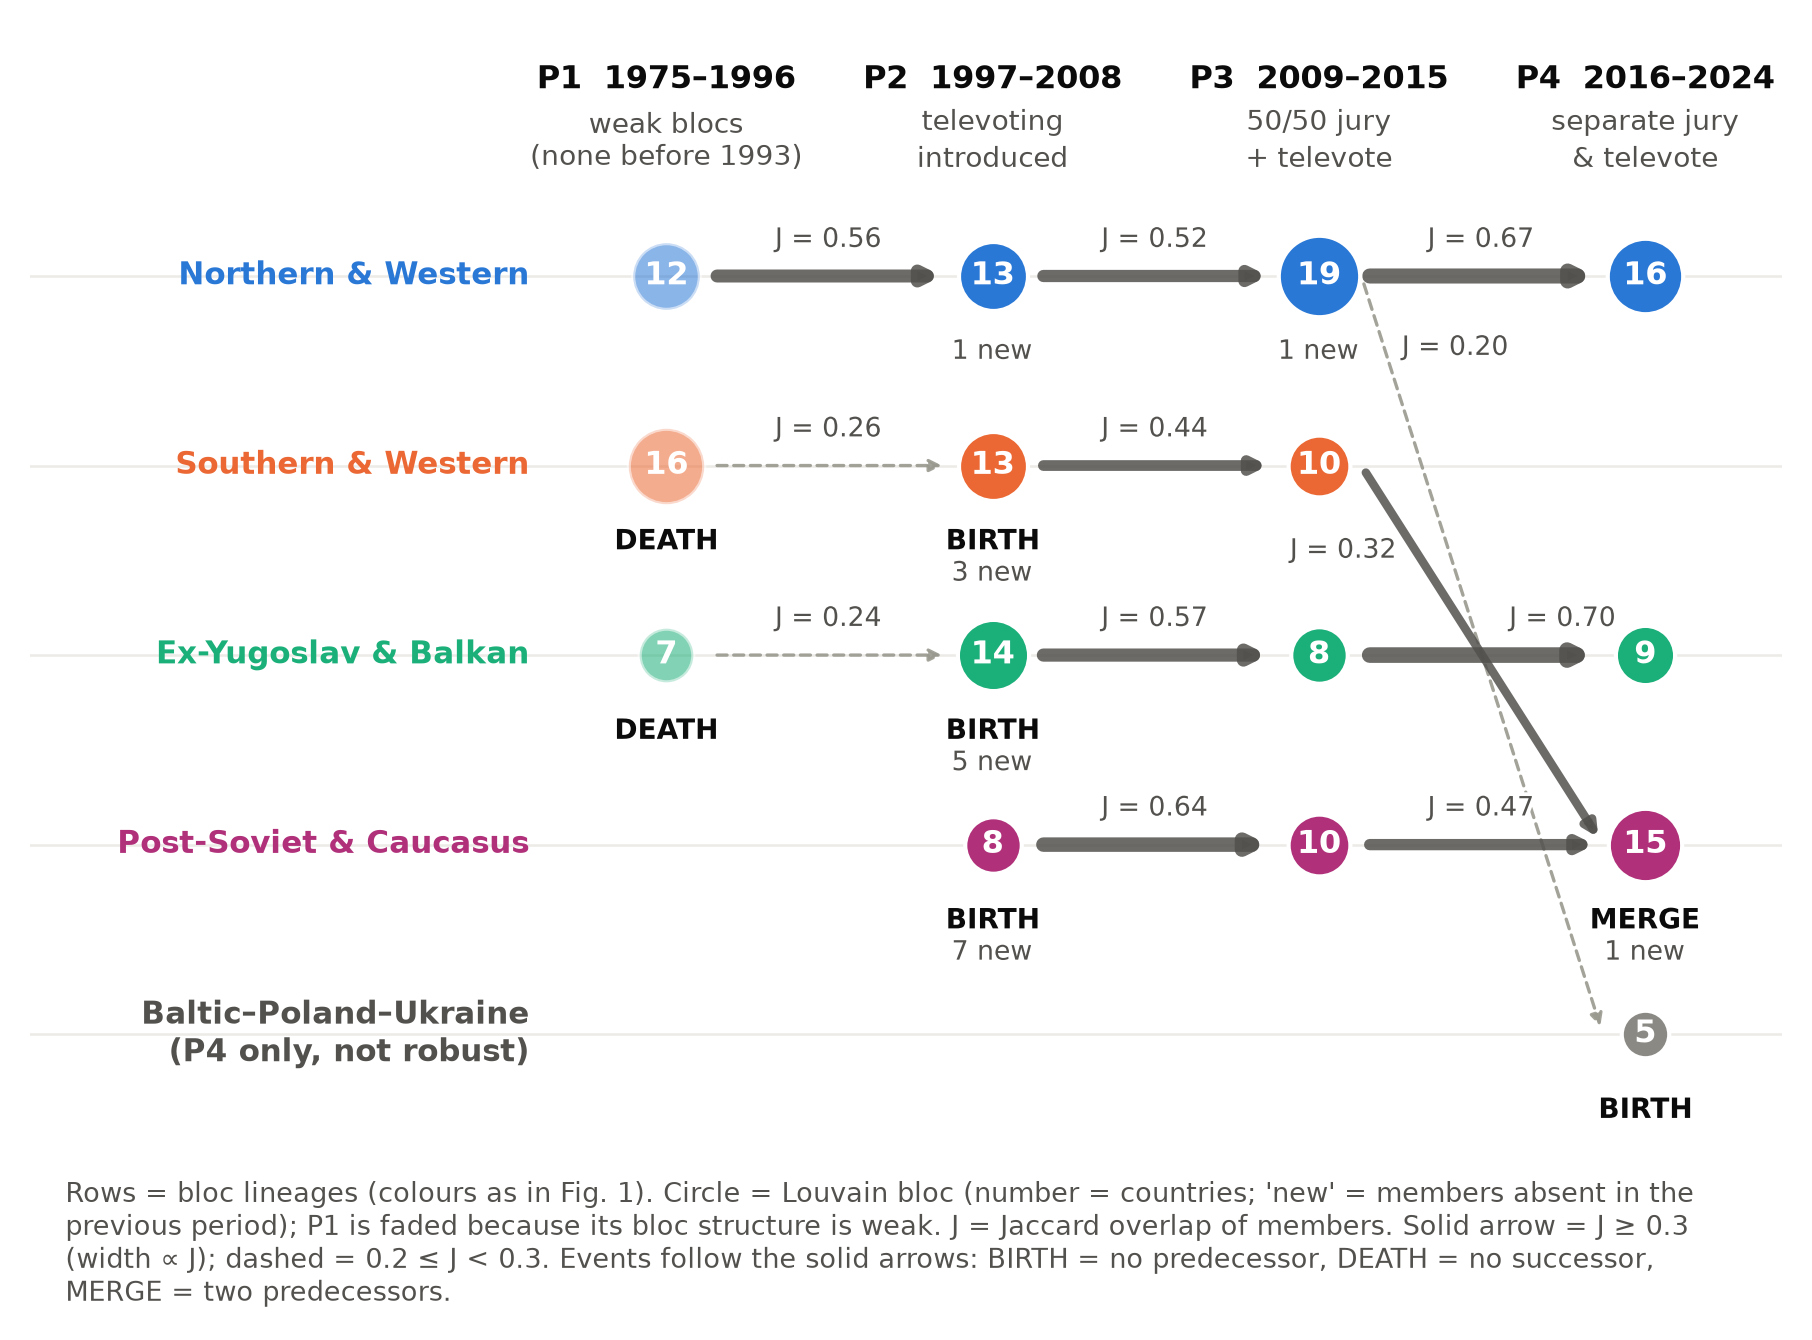

In [36]:
# figure 2: community evolution graph

TH_MAIN, TH_LOW = 0.3, 0.2
ROW = {name: r for r, name in enumerate(LINEAGES)}
X = {p: i for i, p in enumerate(PERIODS)}
size_of = {(p, i): len(b) for p in PERIODS for i, b in enumerate(partitions[p], start=1)}
pos = {k: (X[k[0]], ROW[BLOC_LINEAGE[k]]) for k in size_of}

# new countries of each bloc
present = {p: set(graphs[p].nodes()) for p in PERIODS}
new_in = {}
for prev, p in zip(PERIODS[:-1], PERIODS[1:]):
    for i, b in enumerate(partitions[p], start=1):
        new_in[(p, i)] = len(set(b) - present[prev])

# links between blocs of consecutive periods (Jaccard >= 0.2)
links = []
for _, r in overlap.iterrows():
    if r["jaccard"] >= TH_LOW:
        links.append(((r["from_period"], int(r["from_bloc"])), (r["to_period"], int(r["to_bloc"])),
                      r["jaccard"], int(r["n_shared"])))

# events from the links with Jaccard >= 0.3
main = [(a, b) for a, b, j, n in links if j >= TH_MAIN]
n_in = {k: sum(1 for a, b in main if b == k) for k in size_of}
n_out = {k: sum(1 for a, b in main if a == k) for k in size_of}
def event_in(k):
    if k[0] == "P1": return ""
    return "birth" if n_in[k] == 0 else ("merge" if n_in[k] > 1 else "")
def event_out(k):
    if k[0] == "P4": return ""
    return "death" if n_out[k] == 0 else ("split" if n_out[k] > 1 else "")

fig, ax = plt.subplots(figsize=(5.9, 4.4), dpi=300)

# links: solid = Jaccard >= 0.3, dashed = Jaccard between 0.2 and 0.3
for a, b, j, n in links:
    (x0, y0), (x1, y1) = pos[a], pos[b]
    strong = j >= TH_MAIN
    arrow = FancyArrowPatch((x0 + 0.13, y0), (x1 - 0.13, y1), arrowstyle="-|>", mutation_scale=6,
                            connectionstyle="arc3,rad=0", lw=0.6 + 4.5 * j if strong else 0.8,
                            color=INK2 if strong else "#9a998f", ls="-" if strong else (0, (3, 2)),
                            alpha=0.85 if strong else 0.9, zorder=1)
    ax.add_patch(arrow)
    if y0 == y1:
        f = 0.75 if (a[0] == "P3" and ROW[BLOC_LINEAGE[a]] == ROW["Ex-Yugoslav & Balkan"]) else 0.5
        xm, ym, ha = x0 + (x1 - x0) * f, y0 - 0.12, "center"
    elif strong:
        f = 0.25
        xm, ym, ha = x0 + 0.13 + (x1 - x0 - 0.26) * f - 0.07, y0 + (y1 - y0) * f + 0.02, "right"
    else:
        f = 0.1
        xm, ym, ha = x0 + 0.13 + (x1 - x0 - 0.26) * f + 0.05, y0 + (y1 - y0) * f + 0.05, "left"
    ax.text(xm, ym, f"J = {j:.2f}", ha=ha, va="bottom", fontsize=6.4, color=INK2, zorder=3,
            path_effects=[pe.withStroke(linewidth=1.8, foreground="white")])

# blocs: size = number of countries
for k, (x, y) in pos.items():
    col, mk = LINEAGES[BLOC_LINEAGE[k]]
    transp = 0.55 if k[0] == "P1" else 1.0
    ax.scatter(x, y, s=18 * size_of[k] + 40, c=col, marker="o", edgecolors="white", linewidths=1, alpha=transp, zorder=2)
    ax.text(x, y, str(size_of[k]), ha="center", va="center", fontsize=7.7, fontweight="bold", color="white", zorder=3)
    label_y = y + 0.33
    events = [e for e in (event_in(k), event_out(k)) if e]
    if events:
        ax.text(x, label_y, " · ".join(e.upper() for e in events), ha="center", va="top", fontsize=6.7,
                fontweight="bold", color=INK, zorder=3, path_effects=[pe.withStroke(linewidth=1.8, foreground="white")])
        label_y += 0.17
    if k in new_in and new_in[k] > 0:
        ax.text(x, label_y, f"{new_in[k]} new", ha="center", va="top", fontsize=6.4, color=INK2, zorder=3,
                path_effects=[pe.withStroke(linewidth=1.8, foreground="white")])

# axes and labels
for name, r in ROW.items():
    ax.text(-0.42, r, name.replace(" (P4 only, not robust)", "\n(P4 only, not robust)"), ha="right",
            va="center", fontsize=7.4, color=LINEAGES[name][0] if r < 4 else INK2, fontweight="bold")
    ax.axhline(r, color="#ecebe7", lw=0.6, zorder=0)
HEAD = {"P1": ("P1  1975–1996", "weak blocs\n(none before 1993)"), "P2": ("P2  1997–2008", "televoting\nintroduced"),
        "P3": ("P3  2009–2015", "50/50 jury\n+ televote"), "P4": ("P4  2016–2024", "separate jury\n& televote")}
for p in PERIODS:
    ax.text(X[p], -0.95, HEAD[p][0], ha="center", va="bottom", fontsize=7.7, color=INK, fontweight="bold")
    ax.text(X[p], -0.9, HEAD[p][1], ha="center", va="top", fontsize=6.8, color=INK2, linespacing=1.2)
ax.set_xlim(-1.95, 3.42); ax.set_ylim(4.55, -1.3); ax.axis("off")

fig.text(0.02, 0.02, "Rows = bloc lineages (colours as in Fig. 1). Circle = Louvain bloc (number = countries; 'new' = members absent in the\n"
         "previous period); P1 is faded because its bloc structure is weak. J = Jaccard overlap of members. Solid arrow = J ≥ 0.3\n"
         "(width ∝ J); dashed = 0.2 ≤ J < 0.3. Events follow the solid arrows: BIRTH = no predecessor, DEATH = no successor,\n"
         "MERGE = two predecessors.",
         fontsize=6.5, color=INK2, va="bottom")
plt.subplots_adjust(left=0.0, right=0.99, top=0.99, bottom=0.15)
fig.savefig(FIG + "fig2_bloc_evolution.pdf", facecolor="white")
fig.savefig(FIG + "fig2_bloc_evolution.png", dpi=300, facecolor="white")
plt.show()

### 9.3. Figure 3: Structure Over Time

Modularity, reciprocity and core–periphery fit per period, with the range across the robustness specifications.

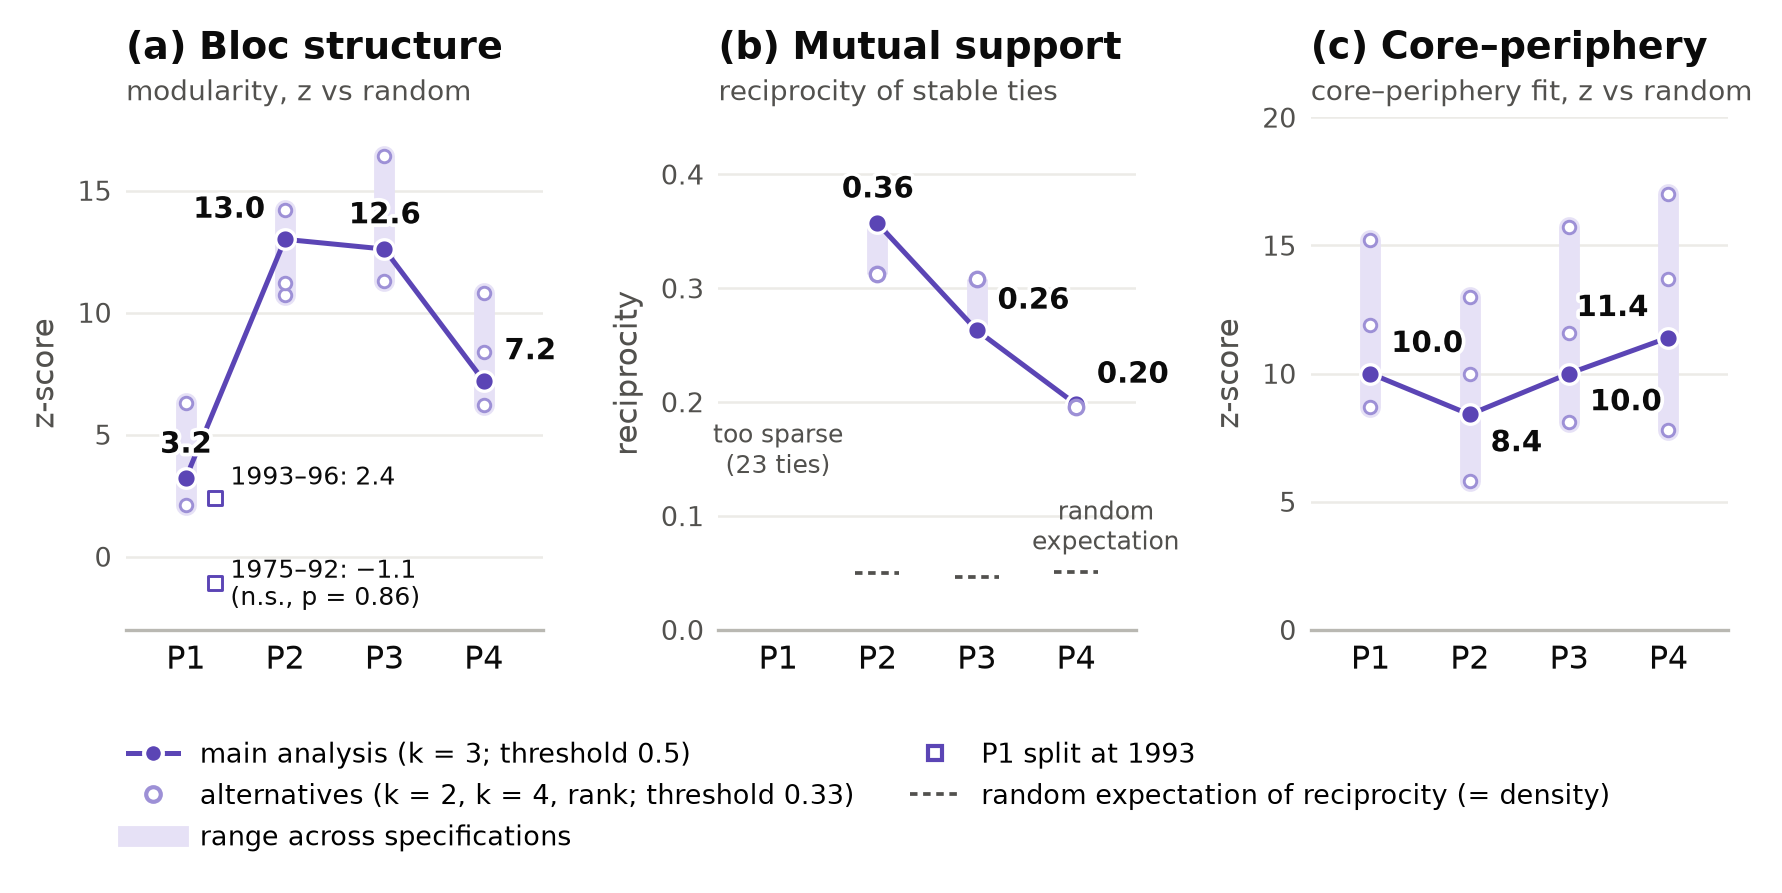

In [37]:
# figure 3: bloc structure over time
MAIN, ALT, BAND = "#5b45b5", "#9d90d6", "#e6e1f6"
xs = np.arange(len(PERIODS))
rob = robust_table.set_index(["period", "variant"])
VARIANTS = ["k=2", "k=4", "rank"]

# values of the main analysis and of the robustness checks
mod_main = perm_table.set_index("period")["z_score"].reindex(PERIODS).values
mod_alt = np.array([[rob.loc[(p, v), "Q_z"] for v in VARIANTS] for p in PERIODS])
cp_main = cp_table.set_index("period")["z_score"].reindex(PERIODS).values
cp_alt = np.array([[rob.loc[(p, v), "CP_z"] for v in VARIANTS] for p in PERIODS])
rec_main = basic_table.set_index("period")["reciprocity"].reindex(PERIODS).values
rec_alt = t033_table.set_index("period")["reciprocity"].reindex(PERIODS).values
z_p1a, z_p1b = rob.loc[("P1a", "k=3"), "Q_z"], rob.loc[("P1b", "k=3"), "Q_z"]

fig, axes = plt.subplots(1, 3, figsize=(5.9, 3.05), dpi=300)

def style(ax, title, subtitle, ylabel):
    ax.set_title(title, loc="left", fontsize=9, fontweight="bold", color=INK, pad=14)
    ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=6.8, color=INK2, va="bottom")
    ax.set_xticks(xs); ax.set_xticklabels(PERIODS, fontsize=7.7, color=INK)
    ax.set_xlim(-0.6, 3.6)
    ax.set_ylabel(ylabel, fontsize=7.4, color=INK2)
    ax.tick_params(axis="y", labelsize=6.5, colors=INK2, length=0)
    ax.tick_params(axis="x", length=0)
    ax.grid(axis="y", color="#ecebe7", lw=0.6); ax.set_axisbelow(True)
    for s in ["top", "right", "left"]:
        ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color("#b9b8b2")

def range_and_main(ax, main, alt, fmt):
    lo, hi = np.minimum(alt.min(axis=1), main), np.maximum(alt.max(axis=1), main)
    ax.vlines(xs, lo, hi, color=BAND, lw=5, zorder=1, capstyle="round")
    ax.scatter(np.repeat(xs, alt.shape[1]), alt.ravel(), s=9, facecolor="white",
               edgecolor=ALT, lw=0.7, zorder=2)
    ax.plot(xs, main, color=MAIN, lw=1.2, zorder=3)
    ax.scatter(xs, main, s=22, color=MAIN, edgecolor="white", lw=0.8, zorder=4)
    put_labels(ax, xs, main, alt, fmt)

def put_labels(ax, x_pos, main, alt, fmt):
    # value labels
    y0, y1 = ax.get_ylim(); span = y1 - y0
    for i, (x, v, others) in enumerate(zip(x_pos, main, alt)):
        others = np.atleast_1d(others)
        up_free = not np.any((others > v + 0.02 * span) & (others < v + 0.14 * span))
        next_up = i + 1 < len(main) and main[i + 1] > v + 0.02 * span
        prev_up = i > 0 and main[i - 1] > v + 0.02 * span
        steep_in = i > 0 and main[i - 1] > v + 0.08 * span
        if up_free and not steep_in: xy, ha, va = (0, 4.5), "center", "bottom"
        elif i == 0 and not next_up: xy, ha, va = (5, 3.5), "left", "bottom"
        elif not prev_up and next_up: xy, ha, va = (5, -3.5), "left", "top"
        elif not prev_up:            xy, ha, va = (-5, 3.5), "right", "bottom"
        elif not next_up:            xy, ha, va = (5, 3.5), "left", "bottom"
        else:                        xy, ha, va = (5, -3.5), "left", "top"
        ax.annotate(fmt.format(v), (x, v), xytext=xy, textcoords="offset points", ha=ha, va=va,
                    fontsize=7, color=INK, fontweight="bold", zorder=5,
                    path_effects=[pe.withStroke(linewidth=1.8, foreground="white")])

# (a) modularity vs random
ax = axes[0]
ax.set_ylim(-3, 18)
range_and_main(ax, mod_main, mod_alt, "{:.1f}")
ax.scatter([0.3, 0.3], [z_p1a, z_p1b], marker="s", s=12, facecolor="white", edgecolor=MAIN, lw=0.7, zorder=4)
p_p1a = rob.loc[("P1a", "k=3"), "Q_p"]
ax.text(0.45, z_p1a, f"1975–92: {z_p1a:.1f}\n(n.s., p = {p_p1a:.2f})".replace("-", "−"), fontsize=6.1, color=INK,
        ha="left", va="center", linespacing=1.15)
ax.text(0.45, z_p1b + 0.3, f"1993–96: {z_p1b:.1f}", fontsize=6.1, color=INK, ha="left", va="bottom")
ax.set_yticks([0, 5, 10, 15])
style(ax, "(a) Bloc structure", "modularity, z vs random", "z-score")

# (b) reciprocity
ax = axes[1]
ax.set_ylim(0, 0.45)
dens = basic_table.set_index("period")["density_binary"].reindex(PERIODS).values
ax.hlines(dens[1:], xs[1:] - 0.22, xs[1:] + 0.22, color=INK2, lw=0.9, ls=(0, (2, 1.5)), zorder=2)
ax.text(3.3, dens[3] + 0.012, "random\nexpectation", fontsize=6, color=INK2, ha="center", va="bottom")
ax.plot(xs[1:], rec_main[1:], color=MAIN, lw=1.2, zorder=3)
ax.scatter(xs[1:], rec_main[1:], s=22, color=MAIN, edgecolor="white", lw=0.8, zorder=4)
ax.scatter(xs[1:], rec_alt[1:], s=12, facecolor="white", edgecolor=ALT, lw=0.8, zorder=4)
ax.vlines(xs[1:], np.minimum(rec_main, rec_alt)[1:], np.maximum(rec_main, rec_alt)[1:],
          color=BAND, lw=5, zorder=1)
put_labels(ax, xs[1:], rec_main[1:], rec_alt[1:], "{:.2f}")
ax.text(0, 0.13, "too sparse\n(23 ties)", fontsize=6.1, color=INK2, ha="center", va="bottom")
ax.set_yticks([0, 0.1, 0.2, 0.3, 0.4])
style(ax, "(b) Mutual support", "reciprocity of stable ties", "reciprocity")

# (c) core-periphery
ax = axes[2]
ax.set_ylim(0, 20)
range_and_main(ax, cp_main, cp_alt, "{:.1f}")
ax.set_yticks([0, 5, 10, 15, 20])
style(ax, "(c) Core–periphery", "core–periphery fit, z vs random", "z-score")

# legend
handles = [Line2D([], [], color=MAIN, marker="o", ms=4.5, mec="white", lw=1.2, label="main analysis (k = 3; threshold 0.5)"),
           Line2D([], [], color=ALT, marker="o", ms=3.5, mfc="white", lw=0, label="alternatives (k = 2, k = 4, rank; threshold 0.33)"),
           Line2D([], [], color=BAND, lw=5, label="range across specifications"),
           Line2D([], [], color=MAIN, marker="s", ms=3.5, mfc="white", lw=0, label="P1 split at 1993"),
           Line2D([], [], color=INK2, lw=0.9, ls=(0, (2, 1.5)), label="random expectation of reciprocity (= density)")]
fig.legend(handles=handles, loc="lower center", ncol=2, fontsize=6.6, frameon=False, bbox_to_anchor=(0.5, 0.0),
           columnspacing=2.0, handlelength=1.8)
plt.subplots_adjust(left=0.08, right=0.985, top=0.83, bottom=0.27, wspace=0.42)

fig.savefig(FIG + "fig3_structure_over_time.pdf", facecolor="white")
fig.savefig(FIG + "fig3_structure_over_time.png", dpi=300, facecolor="white")
plt.show()

## 10. Sensitivity Check of the Permutation Test

The observed Q of the main analysis is the best of 100 Louvain runs, but each null network uses the best of 10 runs. A fair comparison should use the same procedure on both sides, so the observed Q is recomputed with the best of 10 runs and the z-scores and p-values are checked again.

In [38]:
# check: networks are directed and NetworkX >= 3.0
print("NetworkX version:", nx.__version__)
print("Graph type:", type(graphs["P2"]).__name__)

# check: observed Q with the same Louvain procedure as the null networks
for p in PERIODS:
    G = graphs[p]
    q10 = max(
        nx.community.modularity(G, nx.community.louvain_communities(G, weight="weight", seed=s), weight="weight")
        for s in range(10)
    )
    print(p, "best of 100 seeds:", round(modularity_obs[p], 4), "| best of 10 seeds:", round(q10, 4))

NetworkX version: 3.7
Graph type: DiGraph
P1 best of 100 seeds: 0.1801 | best of 10 seeds: 0.1785
P2 best of 100 seeds: 0.2982 | best of 10 seeds: 0.2973
P3 best of 100 seeds: 0.2974 | best of 10 seeds: 0.2974
P4 best of 100 seeds: 0.2066 | best of 10 seeds: 0.2066


In [39]:
# results stored by the permutation test and the robustness checks
print(perm_table)
print(robust_table[robust_table["period"].isin(["P1a", "P1b"])])
for k, v in list(globals().items()):
    if any(w in k.lower() for w in ["null", "perm", "rand"]) and not k.startswith("_"):
        print(k, "->", type(v).__name__)

  period  n_blocs  Q_observed  Q_null_mean  Q_null_sd  Q_null_max  z_score  \
0     P1        3       0.180        0.151      0.009       0.181      3.2   
1     P2        4       0.298        0.189      0.008       0.215     13.0   
2     P3        4       0.297        0.189      0.009       0.212     12.6   
3     P4        4       0.207        0.153      0.008       0.181      7.2   

   p_value  
0    0.006  
1    0.002  
2    0.002  
3    0.002  
   period variant  n_blocs      Q  Q_z    Q_p  NMI_vs_main  CP_z
12    P1a     k=3        4  0.089 -1.1  0.861         0.29   8.9
13    P1b     k=3        4  0.238  2.4  0.020         0.46   9.7
uman_random_graph -> function
N_PERM -> int
perm_results -> list
null_q -> dict
nulls -> ndarray
A_rand -> DataFrame
G_rand -> DiGraph
q_rand -> float
perm_table -> DataFrame
N_RAND -> int
random_counts -> DataFrame
N_PERM_ROB -> int
q_null -> ndarray
fit_null -> ndarray


In [40]:
# P1: z and p with the observed Q from the same procedure as the null networks
G = graphs["P1"]
q10 = max(
    nx.community.modularity(G, nx.community.louvain_communities(G, weight="weight", seed=s), weight="weight")
    for s in range(10)
)
nq = np.array(null_q["P1"])
b_new = int((nq >= q10).sum())
b_old = int((nq >= modularity_obs["P1"]).sum())

print("P1 null networks:", len(nq))
print("Old (best of 100 seeds): Q =", round(modularity_obs["P1"], 4), "| b =", b_old, "| p =", round((b_old + 1) / (len(nq) + 1), 3))
print("New (best of 10 seeds):  Q =", round(q10, 4), "| b =", b_new, "| p =", round((b_new + 1) / (len(nq) + 1), 3),
      "| z =", round((q10 - nq.mean()) / nq.std(), 2))

# content of q_null
print("q_null: n =", len(q_null), "| mean =", round(float(np.mean(q_null)), 4), "| max =", round(float(np.max(q_null)), 4))

P1 null networks: 500
Old (best of 100 seeds): Q = 0.1801 | b = 2 | p = 0.006
New (best of 10 seeds):  Q = 0.1785 | b = 2 | p = 0.006 | z = 3.01
q_null: n = 200 | mean = 0.2078 | max = 0.2484


In [41]:
# graphs and dictionaries in memory
for k, v in list(globals().items()):
    if k.startswith("_"):
        continue
    if isinstance(v, nx.DiGraph):
        print(k, "-> DiGraph with", v.number_of_nodes(), "nodes")
    elif isinstance(v, dict) and len(v) > 0:
        print(k, "-> dict, keys:", list(v.keys())[:6])

Out -> dict, keys: [7, 8, 9, 10, 15, 23]
adj -> dict, keys: ['P1', 'P2', 'P3', 'P4']
graphs -> dict, keys: ['P1', 'P2', 'P3', 'P4']
G -> DiGraph with 35 nodes
partitions -> dict, keys: ['P1', 'P2', 'P3', 'P4']
modularity_obs -> dict, keys: ['P1', 'P2', 'P3', 'P4']
null_q -> dict, keys: ['P1', 'P2', 'P3', 'P4']
G_rand -> DiGraph with 45 nodes
blocs_of -> dict, keys: ['P1', 'P2', 'P3', 'P4']
countries_of -> dict, keys: ['P1', 'P2', 'P3', 'P4']
bin_graphs -> dict, keys: ['P1', 'P2', 'P3', 'P4']
TRIAD_GROUPS -> dict, keys: ['102_mutual_pair', '021U_common_target', '021D_one_voter_two_targets', '030T_transitive', 'bloc_like_mutual_closed']
observed -> dict, keys: ['003', '012', '102', '021D', '021U', '021C']
Gb -> DiGraph with 45 nodes
in_str -> dict, keys: ['ALB', 'ARM', 'AUS', 'AUT', 'AZE', 'BEL']
btw -> dict, keys: ['ALB', 'ARM', 'AUS', 'AUT', 'AZE', 'BEL']
bloc_of -> dict, keys: ['NOR', 'DEU', 'ISL', 'FIN', 'AUS', 'HUN']
alt_nets -> dict, keys: [('P1', 'k=2'), ('P1', 'k=4'), ('P1', 'ran

In [42]:
# P1b: z and p with the observed Q from the same procedure as the null networks
key = ("P1b", "k=3")
obj = alt_nets[key]
print("Stored as:", type(obj).__name__)
G1b = obj if isinstance(obj, nx.DiGraph) else nx.from_pandas_adjacency(obj, create_using=nx.DiGraph)

# Louvain with seeds 0-99 (the first 10 give the best-of-10 value)
qs = [nx.community.modularity(G1b, nx.community.louvain_communities(G1b, weight="weight", seed=s), weight="weight")
      for s in range(100)]
q100, q10 = max(qs), max(qs[:10])

nq = np.array(q_null)
for name, q in [("best of 100", q100), ("best of 10", q10)]:
    b = int((nq >= q).sum())
    print(name, "| Q =", round(q, 4), "| b =", b, "| p =", round((b + 1) / (len(nq) + 1), 3),
          "| z =", round((q - nq.mean()) / nq.std(), 2))

Stored as: DataFrame
best of 100 | Q = 0.2376 | b = 3 | p = 0.02 | z = 2.38
best of 10 | Q = 0.2376 | b = 3 | p = 0.02 | z = 2.38
